# DSCI 552 - Homework 5

**Name:** Yiming Xiong  
**USC ID:** 1057091668

## Import Section

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from xgboost import XGBRegressor

# 1 Decision Trees as Interpretable Models

## 1(a)

In [6]:
DIAGNOSIS_PATH = Path("../data/diagnosis.data")

DIAGNOSIS_COLUMNS = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethral_burning",
    "bladder_inflammation",
    "nephritis",
]

diagnosis_df = pd.read_csv(
    DIAGNOSIS_PATH,
    sep="\t",
    header=None,
    decimal=",",
    encoding="utf-16",
)
diagnosis_df.columns = DIAGNOSIS_COLUMNS

print(f"Dataset shape: {diagnosis_df.shape}")
display(diagnosis_df.head())

Dataset shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethral_burning,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


## 1(b) Decision tree

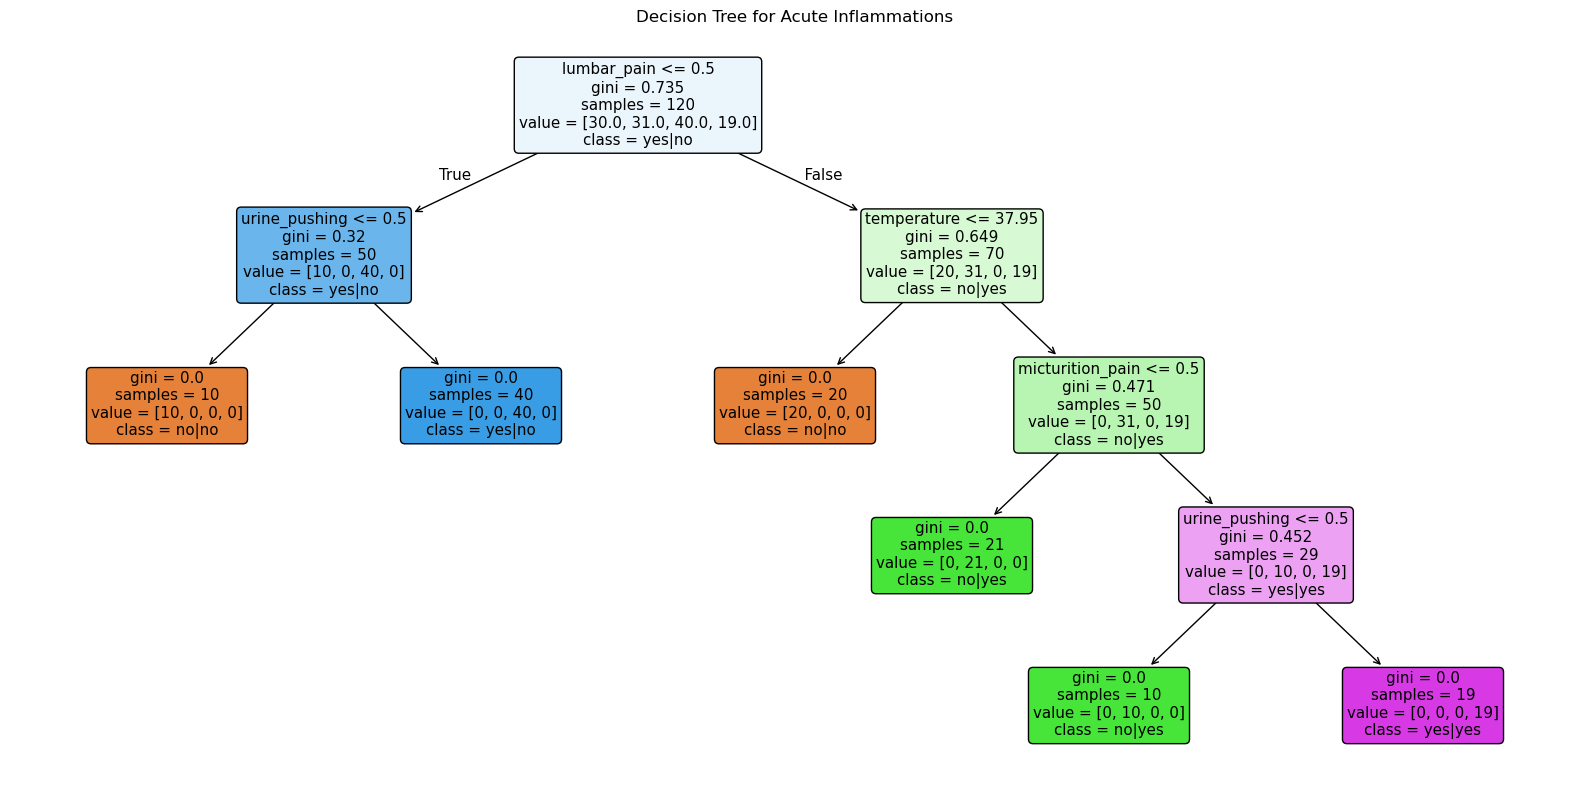

,count
diagnosis_combination,
yes|no,40
no|yes,31
no|no,30
yes|yes,19


In [7]:
target_cols = ["bladder_inflammation", "nephritis"]

X_tree = diagnosis_df.drop(columns=target_cols).copy()
binary_cols = X_tree.select_dtypes(include="object").columns
X_tree[binary_cols] = X_tree[binary_cols].apply(
    lambda col: col.map({"no": 0, "yes": 1})
)
y_tree = (
    diagnosis_df[target_cols]
    .apply(lambda col: col.str.strip().str.lower())
    .agg("|".join, axis=1)
)

tree_model = DecisionTreeClassifier(random_state=552)
tree_model.fit(X_tree, y_tree)

plt.figure(figsize=(16, 8))
plot_tree(
    tree_model,
    feature_names=X_tree.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
)
plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

display(
    y_tree.value_counts()
    .rename_axis("diagnosis_combination")
    .to_frame("count")
)

Label Powerset is suitable here because all four diagnosis combinations occur in the data. It treats each pair of diagnoses as one class and preserves their joint patterns.

## 1(c) IF-THEN Rules

In [8]:
tree = tree_model.tree_
leaf_ids = tree_model.apply(X_tree)

def print_rules(node, conditions):
    if tree.feature[node] < 0:
        sample_index = np.flatnonzero(leaf_ids == node)[0]
        prediction = tree_model.predict(X_tree.iloc[[sample_index]])[0]

        if_part = " AND ".join(conditions) if conditions else "TRUE"
        then_part = " AND ".join(
            f"{column} = {label}"
            for column, label in zip(target_cols, prediction.split("|"))
        )
        print(f"IF {if_part} THEN {then_part}")
        return

    feature = X_tree.columns[tree.feature[node]]
    threshold = tree.threshold[node]

    print_rules(
        tree.children_left[node],
        conditions + [f"{feature} <= {threshold:.2f}"],
    )
    print_rules(
        tree.children_right[node],
        conditions + [f"{feature} > {threshold:.2f}"],
    )

print_rules(0, [])

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN bladder_inflammation = no AND nephritis = no
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN bladder_inflammation = yes AND nephritis = no
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN bladder_inflammation = no AND nephritis = no
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain <= 0.50 THEN bladder_inflammation = no AND nephritis = yes
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN bladder_inflammation = no AND nephritis = yes
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN bladder_inflammation = yes AND nephritis = yes


## 1(d) Cost-complexity pruning

In [9]:
path = tree_model.cost_complexity_pruning_path(X_tree, y_tree)
alphas = path.ccp_alphas[:-1]  # Exclude the root-only tree

pruning_search = GridSearchCV(
    DecisionTreeClassifier(random_state=552),
    {"ccp_alpha": alphas},
    cv=5,
    scoring="accuracy",
)
pruning_search.fit(X_tree, y_tree)

scores = pruning_search.cv_results_["mean_test_score"]
best_score = scores.max()
best_alpha = max(
    alpha
    for alpha, score in zip(alphas, scores)
    if np.isclose(score, best_score)
)

pruned_tree = DecisionTreeClassifier(
    random_state=552,
    ccp_alpha=best_alpha,
)
pruned_tree.fit(X_tree, y_tree)

print(f"Selected ccp_alpha: {best_alpha:.4f}")
print(f"Mean 5-fold CV accuracy: {best_score:.3f}")
print(f"Number of leaves: {pruned_tree.get_n_leaves()}")

Selected ccp_alpha: 0.0000
Mean 5-fold CV accuracy: 0.958
Number of leaves: 6


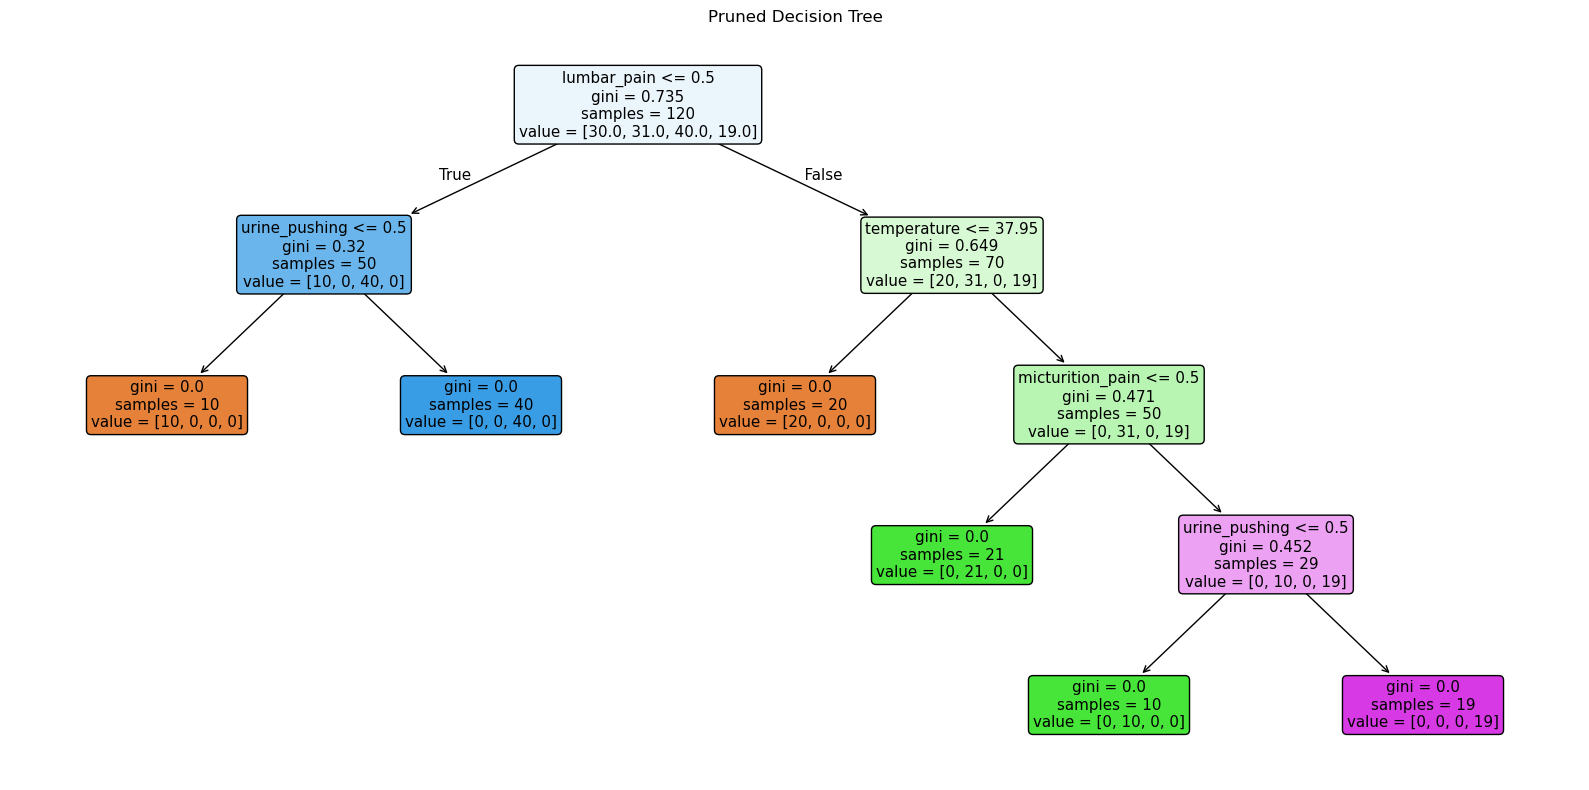

In [10]:
plt.figure(figsize=(16, 8))
plot_tree(
    pruned_tree,
    feature_names=X_tree.columns,
    filled=True,
    rounded=True,
)
plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.show()

Cost-complexity pruning with 5-fold cross-validation selected `ccp_alpha = 0`, retaining the 6-leaf tree. Trees with fewer leaves had lower mean CV accuracy, so pruning did not improve the model under this criterion.

# 2 The LASSO and Boosting for Regression

## 2(a)

In [11]:
COMMUNITIES_PATH = Path("../data/communities.data")

communities_df = pd.read_csv(
    COMMUNITIES_PATH,
    header=None,
    na_values="?",
)

train_df = communities_df.iloc[:1495].copy()
test_df = communities_df.iloc[1495:].copy()

print(f"Full dataset shape: {communities_df.shape}")
print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Full dataset shape: (1994, 128)
Training set shape: (1495, 128)
Test set shape: (499, 128)


## 2(b) Data imputation

In [12]:
COMMUNITIES_NAMES_PATH = Path("../data/communities.names")

with open(COMMUNITIES_NAMES_PATH, encoding="utf-8") as file:
    COMMUNITY_COLUMNS = [
        line.split()[1]
        for line in file
        if line.startswith("@attribute ")
    ]

train_df.columns = COMMUNITY_COLUMNS
test_df.columns = COMMUNITY_COLUMNS

nonpredictive_cols = [
    "state",
    "county",
    "community",
    "communityname",
    "fold",
]
target_col = "ViolentCrimesPerPop"

X_train = train_df.drop(columns=nonpredictive_cols + [target_col])
y_train = train_df[target_col].copy()

X_test = test_df.drop(columns=nonpredictive_cols + [target_col])
y_test = test_df[target_col].copy()

missing_train = X_train.isna().sum().sum()
missing_test = X_test.isna().sum().sum()

train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print(f"Predictor features: {X_train.shape[1]}")
print(f"Missing values before imputation: train={missing_train}, test={missing_test}")
print(f"Missing values after imputation: train={X_train.isna().sum().sum()}, test={X_test.isna().sum().sum()}")

Predictor features: 122
Missing values before imputation: train=27633, test=9218
Missing values after imputation: train=0, test=0


## 2(c) Correlation matrix

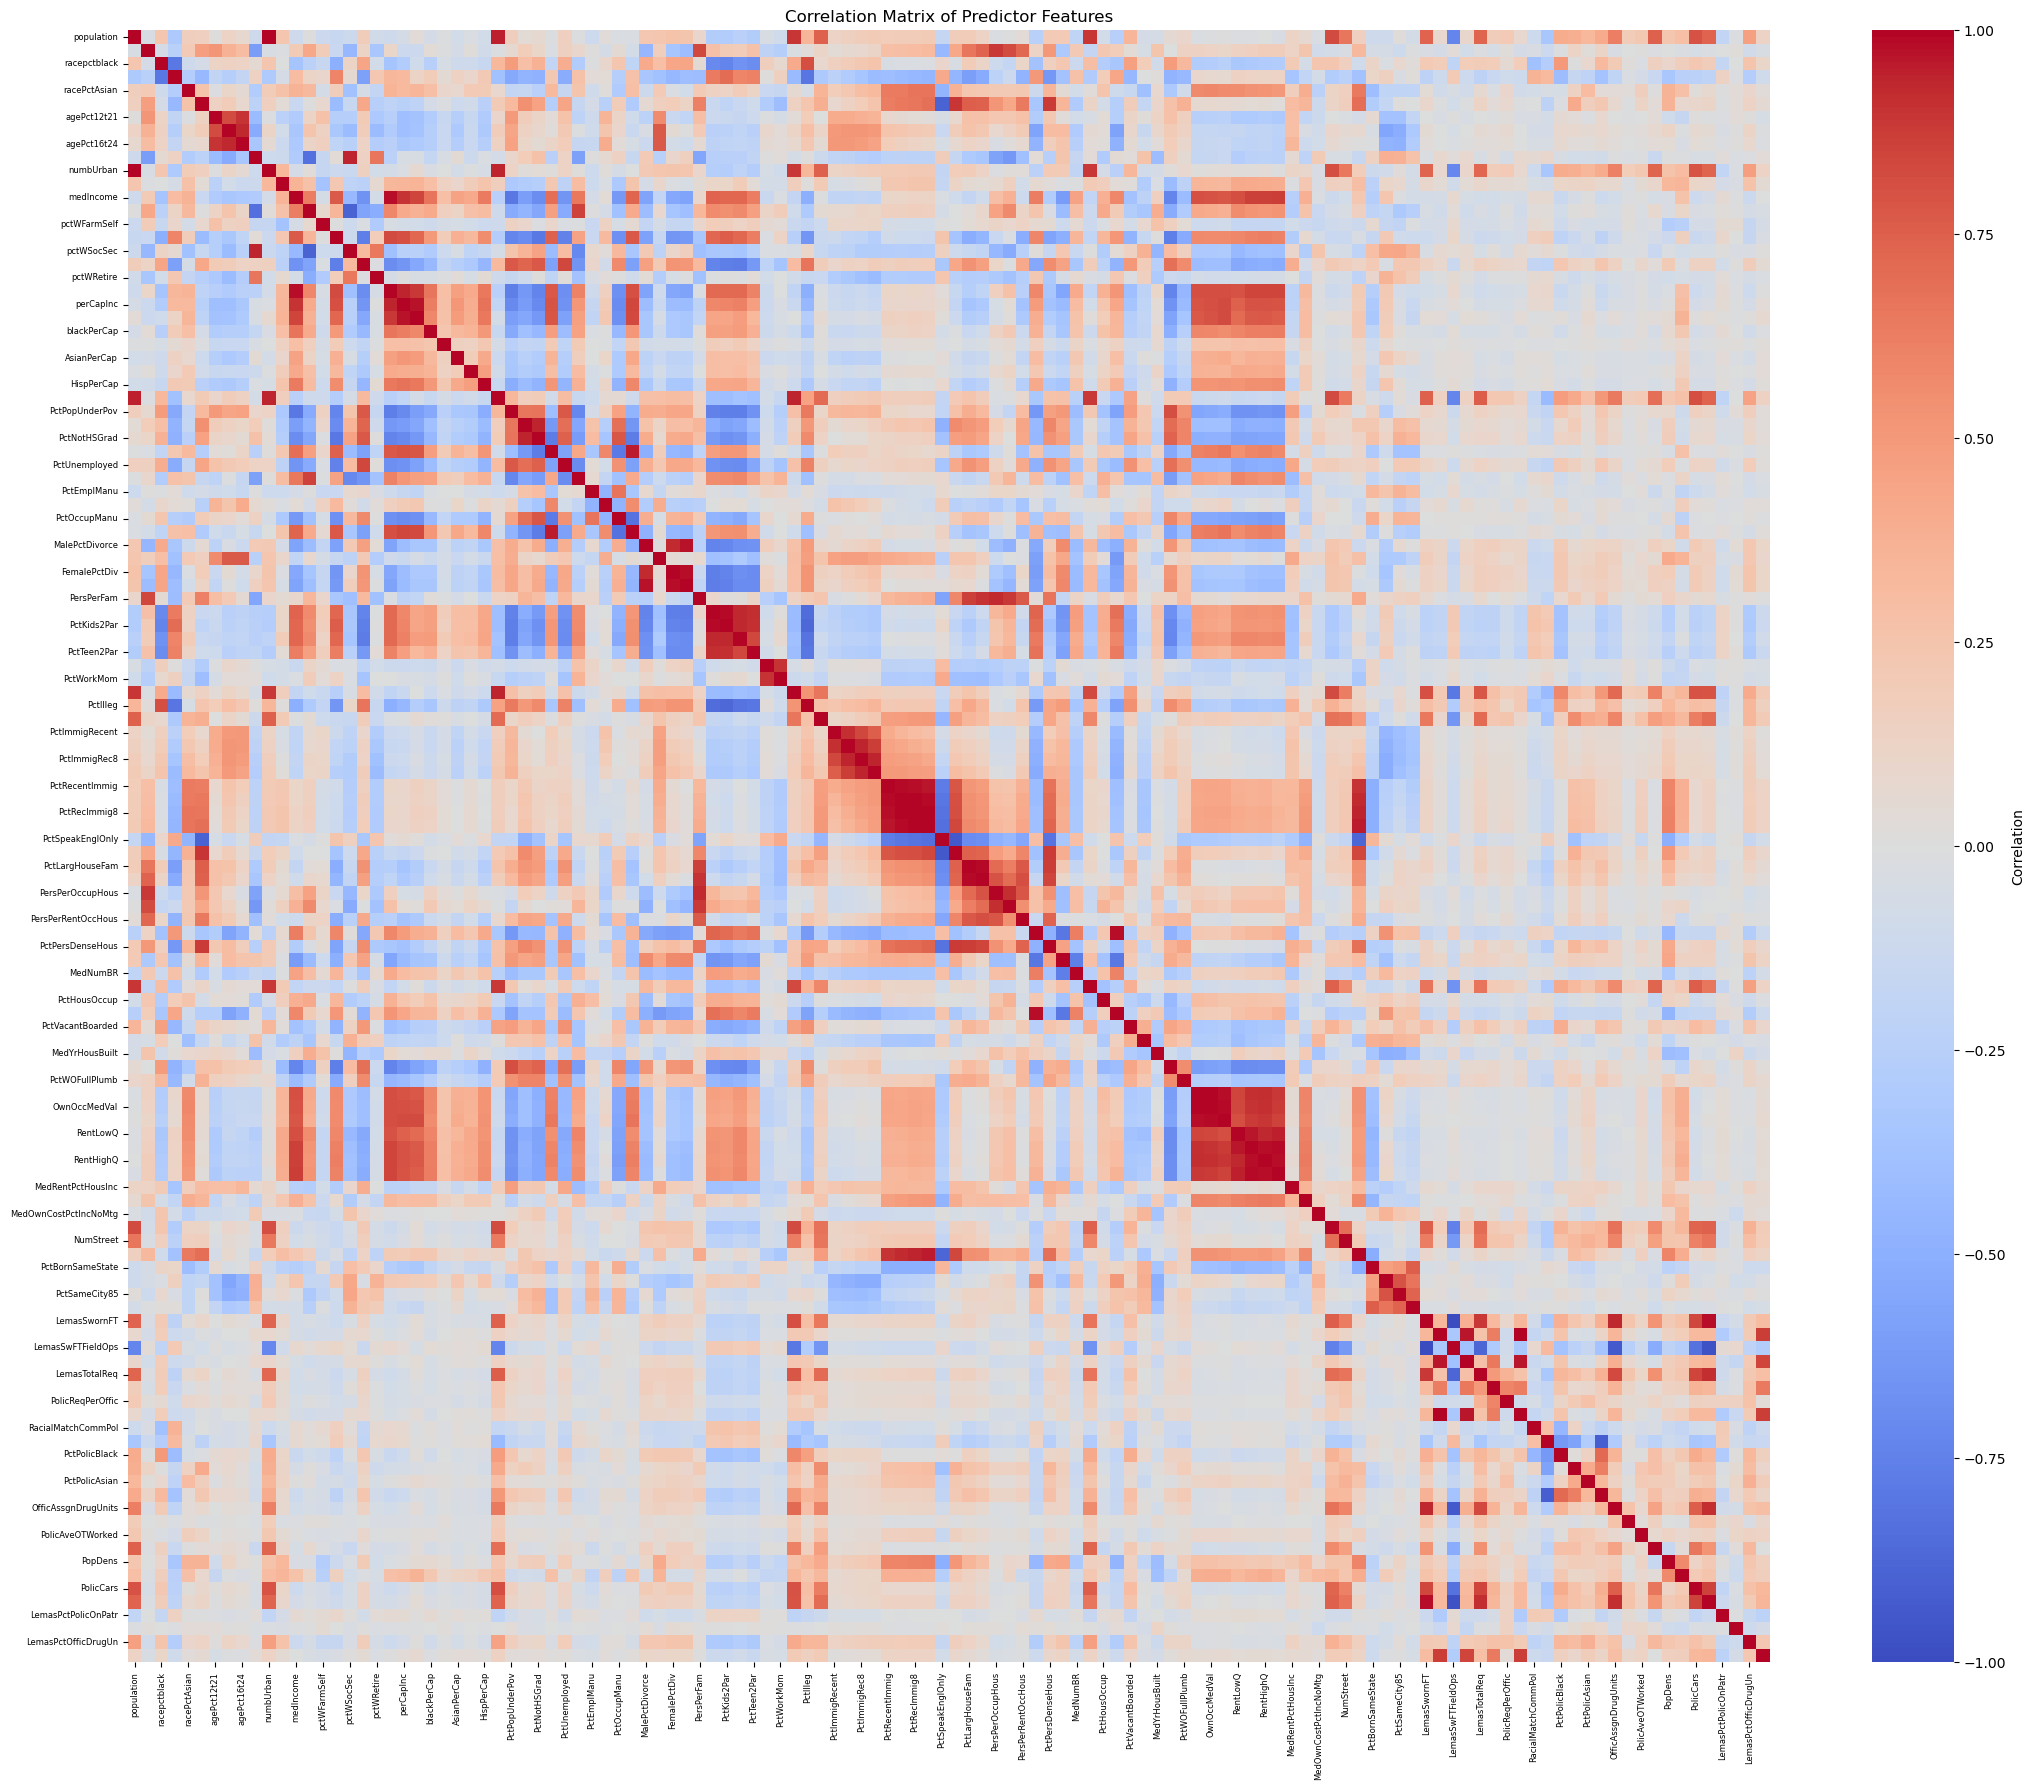

In [13]:
correlation_matrix = X_train.corr()

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    cbar_kws={"label": "Correlation"},
    ax=ax,
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=6)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)
ax.set_title("Correlation Matrix of Predictor Features")

plt.tight_layout()
plt.show()

## 2(d) Coefficient of Variation

In [14]:
feature_mean = X_train.mean()
feature_std = X_train.std(ddof=1)

cv_values = (feature_std / feature_mean).replace([np.inf, -np.inf], np.nan)

cv_table = pd.DataFrame({
    "mean": feature_mean,
    "sample_std": feature_std,
    "CV": cv_values,
}).sort_values("CV", ascending=False)

display(cv_table)

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


## 2(e) The Highest CV Features

In [15]:
n_top_features = int(np.sqrt(128))
top_features = cv_table.dropna(subset=["CV"]).head(n_top_features).index.tolist()

display(cv_table.loc[top_features, ["CV"]])

,CV
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
LemasSwornFT,2.248042
population,2.241105
numbUrban,2.038461


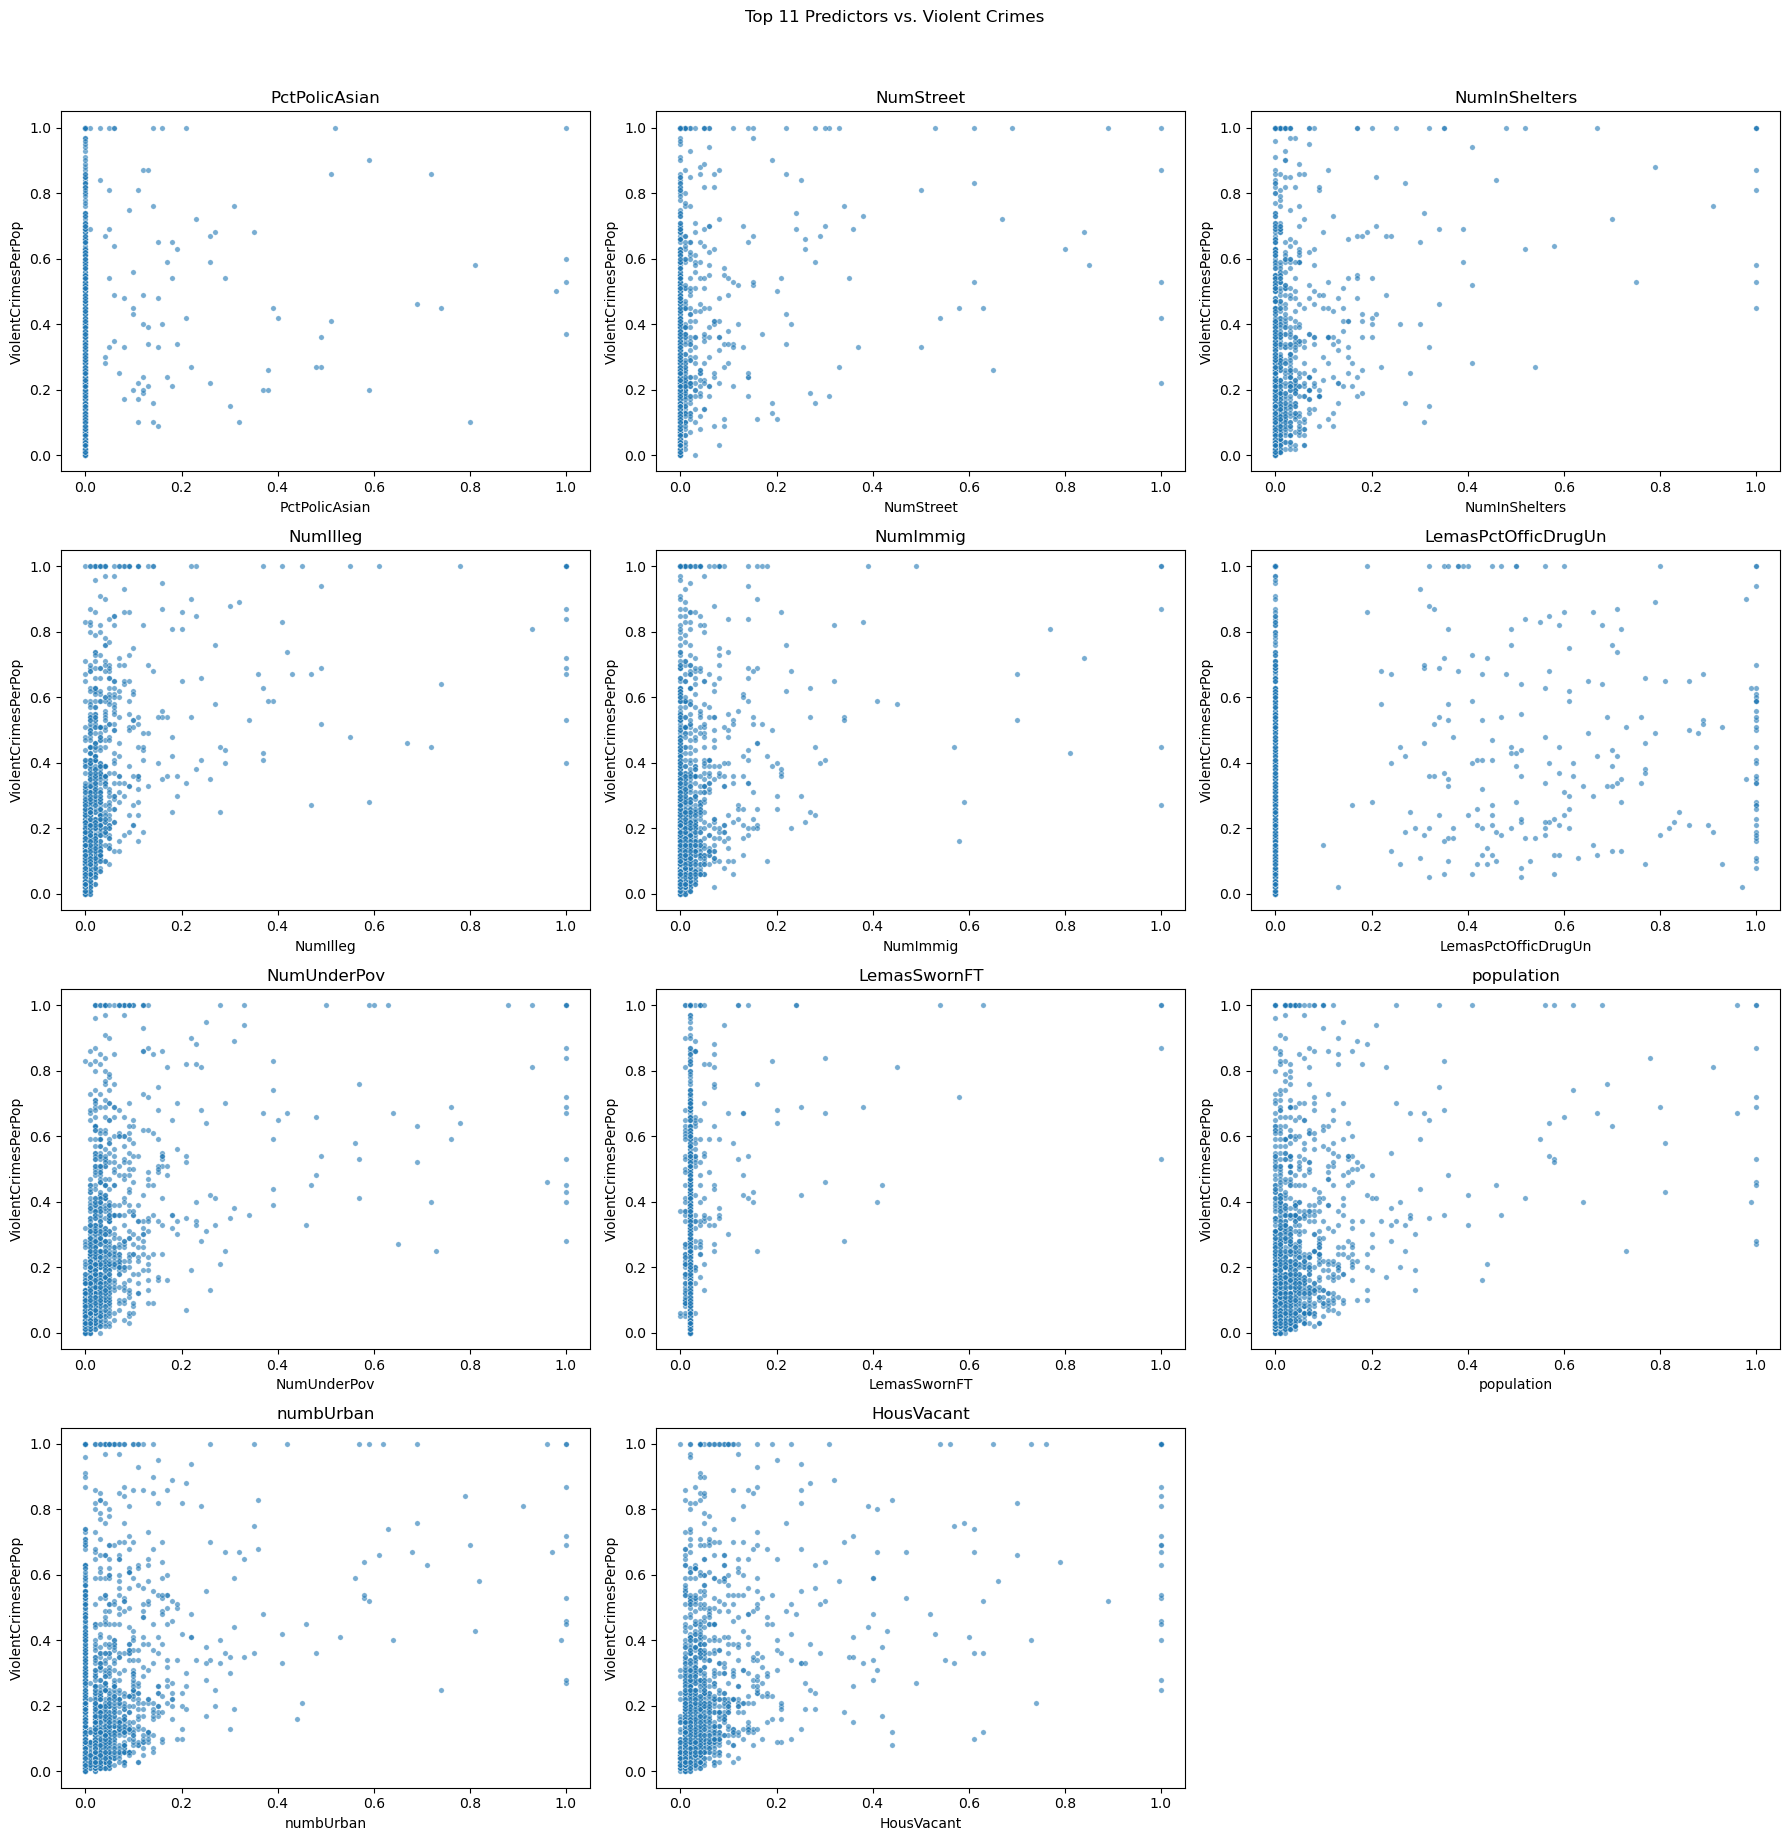

In [16]:
fig, axes = plt.subplots(4, 3, figsize=(18, 18))

for ax, feature in zip(axes.flat, top_features):
    sns.scatterplot(x=X_train[feature], y=y_train, ax=ax, s=15, alpha=0.6)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")

for ax in axes.flat[len(top_features):]:
    ax.remove()

fig.suptitle("Top 11 Predictors vs. Violent Crimes", y=1.02)
plt.tight_layout()
plt.show()

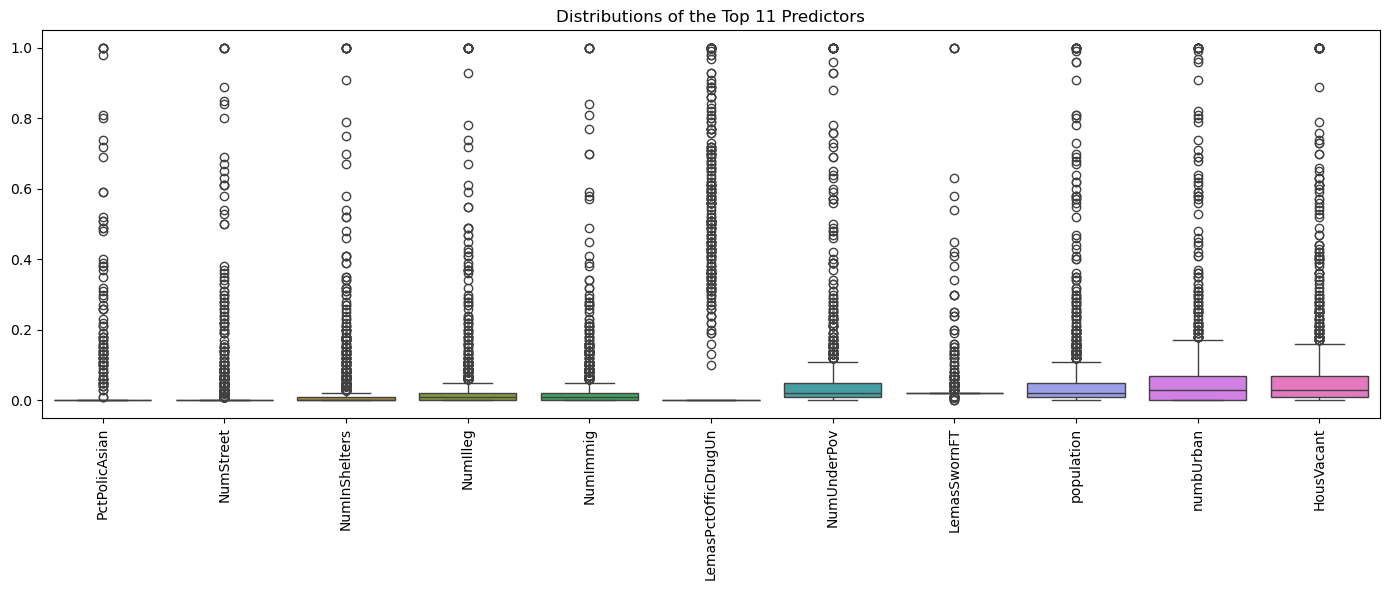

In [17]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=X_train[top_features])
plt.xticks(rotation=90)
plt.title("Distributions of the Top 11 Predictors")
plt.tight_layout()
plt.show()

The plots show possible associations and outliers, but visual inspection alone cannot establish statistical significance.

## 2(f) Least Squares Regression

In [18]:
least_squares_model = LinearRegression()
least_squares_model.fit(X_train, y_train)

y_test_pred = least_squares_model.predict(X_test)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Test MSE: {test_mse:.4f}")

Test MSE: 4293371096614692864.0000


In [19]:
print(
    "Duplicate predictors match:",
    X_train["PolicPerPop"].equals(X_train["LemasSwFTPerPop"]),
)

X_train_ols = X_train.drop(columns=["LemasSwFTPerPop"])
X_test_ols = X_test.drop(columns=["LemasSwFTPerPop"])

ols_model = LinearRegression()
ols_model.fit(X_train_ols, y_train)

ols_test_pred = ols_model.predict(X_test_ols)
ols_test_mse = mean_squared_error(y_test, ols_test_pred)

print(f"Test MSE: {ols_test_mse:.4f}")

Duplicate predictors match: True
Test MSE: 0.0180


`PolicPerPop` and `LemasSwFTPerPop` are identical in this dataset. I removed `LemasSwFTPerPop` for the least squares fit; the test MSE was 0.0180.

## 2(g) Ridge Regression

In [20]:
ridge_alphas = np.logspace(-4, 4, 50)

ridge_cv = GridSearchCV(
    Ridge(),
    param_grid={"alpha": ridge_alphas},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=552),
)

ridge_cv.fit(X_train_ols, y_train)

ridge_model = ridge_cv.best_estimator_
ridge_test_pred = ridge_model.predict(X_test_ols)
ridge_test_mse = mean_squared_error(y_test, ridge_test_pred)

print(f"Selected lambda: {ridge_cv.best_params_['alpha']:.6g}")
print(f"Test MSE: {ridge_test_mse:.8f}")

Selected lambda: 2.55955
Test MSE: 0.01749808


## 2(h) LASSO Regression

In [21]:
lasso_alphas = np.logspace(-5, 0, 60)
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=552)

lasso_cv_raw = GridSearchCV(
    Lasso(max_iter=100000),
    param_grid={"alpha": lasso_alphas},
    scoring="neg_mean_squared_error",
    cv=cv_splitter,
)
lasso_cv_raw.fit(X_train_ols, y_train)

lasso_raw_model = lasso_cv_raw.best_estimator_
lasso_raw_pred = lasso_raw_model.predict(X_test_ols)
lasso_raw_mse = mean_squared_error(y_test, lasso_raw_pred)
lasso_raw_selected = X_train_ols.columns[
    np.abs(lasso_raw_model.coef_) > 1e-8
].tolist()

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100000)),
])

lasso_cv_std = GridSearchCV(
    lasso_pipeline,
    param_grid={"lasso__alpha": lasso_alphas},
    scoring="neg_mean_squared_error",
    cv=cv_splitter,
)
lasso_cv_std.fit(X_train_ols, y_train)

lasso_std_model = lasso_cv_std.best_estimator_
lasso_std_pred = lasso_std_model.predict(X_test_ols)
lasso_std_mse = mean_squared_error(y_test, lasso_std_pred)
lasso_std_selected = X_train_ols.columns[
    np.abs(lasso_std_model.named_steps["lasso"].coef_) > 1e-8
].tolist()

display(pd.DataFrame({
    "feature_scaling": ["Unstandardized", "Standardized"],
    "selected_lambda": [
        lasso_cv_raw.best_params_["alpha"],
        lasso_cv_std.best_params_["lasso__alpha"],
    ],
    "test_mse": [lasso_raw_mse, lasso_std_mse],
    "number_of_selected_features": [
        len(lasso_raw_selected),
        len(lasso_std_selected),
    ],
}))

print("Selected features (unstandardized):")
print(lasso_raw_selected)

print("\nSelected features (standardized):")
print(lasso_std_selected)

,feature_scaling,selected_lambda,test_mse,number_of_selected_features
0,Unstandardized,0.000086,0.017684,78
1,Standardized,0.000602,0.017733,75


Selected features (unstandardized):
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg',

Unstandardized LASSO selected 78 of 121 predictors (test MSE = 0.017684); standardized LASSO selected 75 (test MSE = 0.017733). Their test errors were nearly identical, although they selected slightly different predictors.

## 2(i) Principal Components Regression

In [22]:
pcr_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("linear_regression", LinearRegression()),
])

pcr_cv = GridSearchCV(
    pcr_pipeline,
    param_grid={
        "pca__n_components": range(1, X_train_ols.shape[1] + 1)
    },
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=552),
    n_jobs=-1,
)
pcr_cv.fit(X_train_ols, y_train)

pcr_model = pcr_cv.best_estimator_
pcr_test_pred = pcr_model.predict(X_test_ols)
pcr_test_mse = mean_squared_error(y_test, pcr_test_pred)

print(f"Selected M: {pcr_cv.best_params_['pca__n_components']}")
print(f"Mean 5-fold CV MSE: {-pcr_cv.best_score_:.4f}")
print(f"Test MSE: {pcr_test_mse:.4f}")

Selected M: 93
Mean 5-fold CV MSE: 0.0194
Test MSE: 0.0183


## 2(j) XGBoost Regression

In [23]:
xgb_alphas = np.concatenate(([0.0], np.logspace(-4, 2, 13)))

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=552,
    n_jobs=1,
)

xgb_cv = GridSearchCV(
    xgb_model,
    param_grid={"reg_alpha": xgb_alphas},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=552),
    n_jobs=-1,
)
xgb_cv.fit(X_train_ols, y_train)

xgb_best_model = xgb_cv.best_estimator_
xgb_test_pred = xgb_best_model.predict(X_test_ols)
xgb_test_mse = mean_squared_error(y_test, xgb_test_pred)

print(f"Selected alpha: {xgb_cv.best_params_['reg_alpha']:.6g}")
print(f"Mean 5-fold CV MSE: {-xgb_cv.best_score_:.4f}")
print(f"Test MSE: {xgb_test_mse:.4f}")

Selected alpha: 3.16228
Mean 5-fold CV MSE: 0.0194
Test MSE: 0.0154


Cross-validation selected `reg_alpha = 3.16228`. The mean 5-fold CV MSE was 0.0194, and the test MSE was 0.0154. Among the models evaluated, XGBoost achieved the lowest test MSE on this test set.